In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv('bike_rental_demand_synthetic.csv')

In [ ]:
df.corr(numeric_only=True)

,hour,season,temperature_c,humidity_pct,windspeed,workingday,weather,rental_count
hour,1.000000,0.022697,-0.054549,0.013051,-0.008766,-0.043944,-0.019465,0.055569
season,0.022697,1.000000,0.044263,0.003415,-0.019077,-0.039284,-0.014432,0.157484
temperature_c,-0.054549,0.044263,1.000000,-0.039397,0.026370,0.032480,0.011183,0.810088
humidity_pct,0.013051,0.003415,-0.039397,1.000000,-0.028606,-0.063310,-0.020672,-0.153166
windspeed,-0.008766,-0.019077,0.026370,-0.028606,1.000000,0.004917,-0.002363,-0.038309
workingday,-0.043944,-0.039284,0.032480,-0.063310,0.004917,1.000000,0.021301,0.160049
weather,-0.019465,-0.014432,0.011183,-0.020672,-0.002363,0.021301,1.000000,-0.277535
rental_count,0.055569,0.157484,0.810088,-0.153166,-0.038309,0.160049,-0.277535,1.000000


**Conclusion:**

From the correlation matrix, we can observe that temperature has a strong positive correlation with bike rental demand, while the other features show weak linear correlations. 

In [ ]:
df.corr(numeric_only=True)['rental_count']

hour             0.055569
season           0.157484
temperature_c    0.810088
humidity_pct    -0.153166
windspeed       -0.038309
workingday       0.160049
weather         -0.277535
rental_count     1.000000
Name: rental_count, dtype: float64

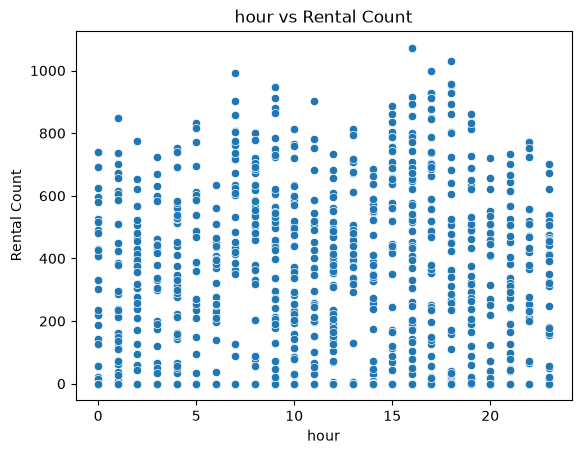

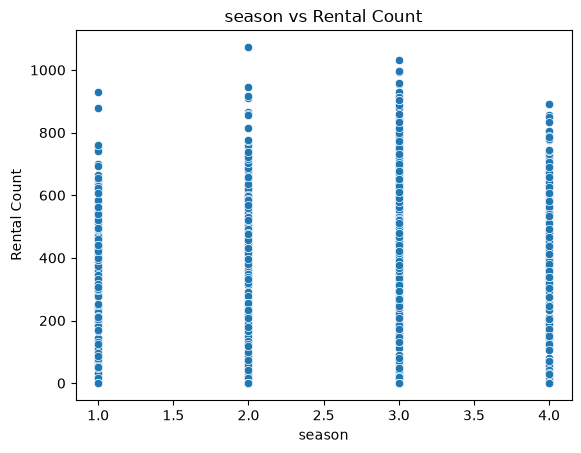

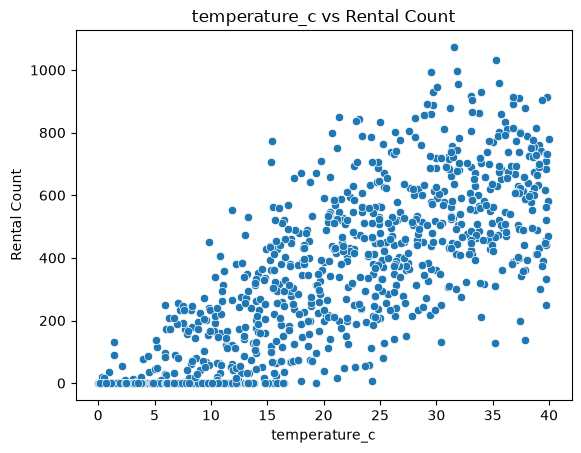

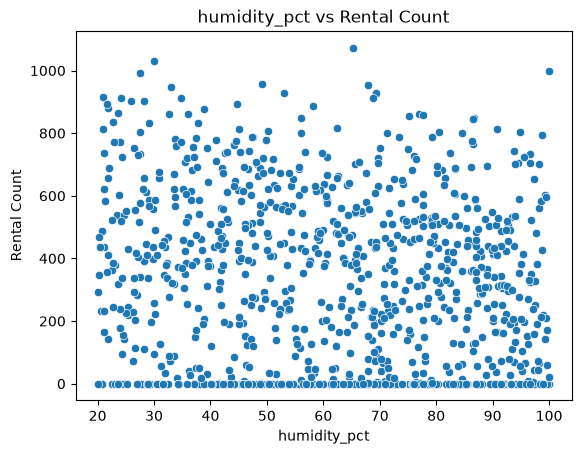

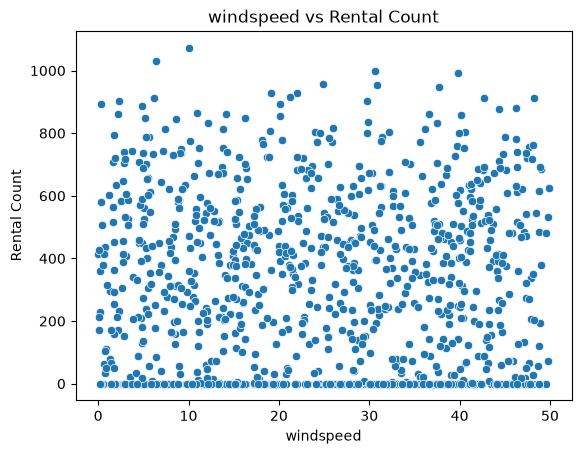

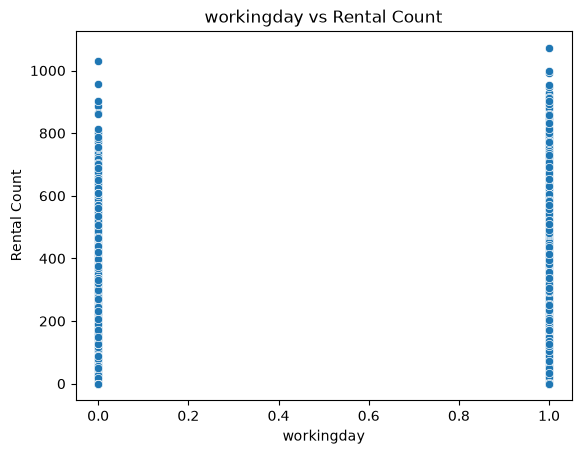

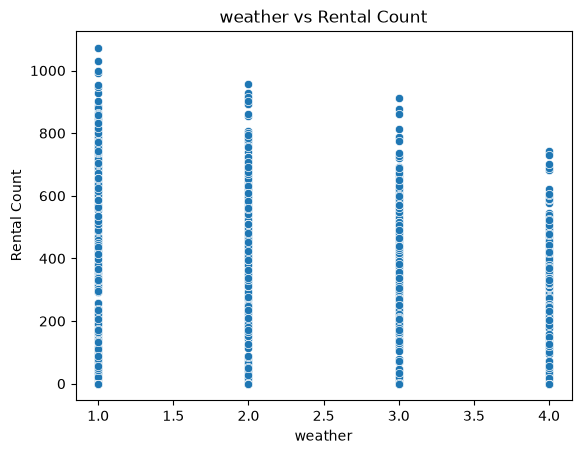

In [ ]:
input_columns = ['hour',	'season',	'temperature_c',	'humidity_pct',	'windspeed',	'workingday',	'weather']

for col in input_columns:
    sns.scatterplot(x=df[col], y=df['rental_count'])
    plt.title(f'{col} vs Rental Count')
    plt.xlabel(col)
    plt.ylabel('Rental Count')
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [ ]:
X = df.drop(columns='rental_count')
Y = df['rental_count']

In [ ]:
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,train_size=0.8,random_state=42)

In [ ]:
xtrain


,hour,season,temperature_c,humidity_pct,windspeed,workingday,weather
29,18,1,23.4,77.7,28.9,1,1
535,6,2,22.7,47.1,38.9,0,4
695,3,3,35.4,69.7,46.2,1,2
557,15,3,22.9,22.8,29.9,1,1
836,18,3,20.7,56.1,39.9,1,1
...,...,...,...,...,...,...,...
106,17,4,22.7,89.0,23.7,1,1
270,4,3,4.5,50.4,33.5,1,1
860,0,4,27.8,43.1,1.6,1,3
435,18,3,3.1,79.0,11.1,0,2


In [ ]:
ytrain


29     607
535    251
695    630
557    837
836    800
      ... 
106    694
270     35
860    515
435     13
102    394
Name: rental_count, Length: 800, dtype: int64

In [ ]:
model=LinearRegression()
model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 3.54, 29.2 , 19.1 ,..., -1.08, 73.28,-74.67]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['hour','season','temperature_c',...,'windspeed','workingday','weather']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,98.11
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [ ]:
model.intercept_    # it is the base/initial value of y when x=0

np.float64(98.10528093518883)

In [ ]:
model.coef_         # it is slope ,also known as weights
                    #the rate of change of y w.r.t x by 1 unit

array([  3.53650691,  29.20117343,  19.10464022,  -1.49258443,
        -1.08331331,  73.28312594, -74.67217873])

In [ ]:
ytrain_predicted=model.predict(xtrain)

In [ ]:
from sklearn.metrics import r2_score

r2_train_score=r2_score(ytrain,ytrain_predicted)
r2_train_score

In [ ]:
# r2 score
# Test score
from sklearn.metrics import r2_score
ytest_predicted=model.predict(xtest)
r2_test_score=r2_score(ytest,ytest_predicted)
r2_test_score

0.7786546568748893

In [ ]:
ytest_predicted=model.predict(xtest)

In [ ]:
from sklearn.metrics import mean_absolute_error
ytest_predicted=model.predict(xtest)
mae_test_score=mean_absolute_error(ytest,ytest_predicted)
mae_test_score

102.02723154346691

In [ ]:
from sklearn.metrics import root_mean_squared_error
ytest_predicted=model.predict(xtest)
rmse_test_score=root_mean_squared_error(ytest,ytest_predicted)
rmse_test_score

123.78414032190985